# IMAGO Hackathon | RGB Greenspace (North East, LSOA)

A short guide to the greenspace data supplied for the North East
study area. Load, explore, analyse and visualise the available
greenspace indicators.


##  Dataset overview

- **Product:** RGB Greenspace Statistics per geometry (2024).
- **Area supplied for this hackathon:** North East study area only. This file is a subset, not the full national dataset.
- **Geography:** LSOA (small-area boundaries).
- **What it measures:** area and share of pixels classified as greenspace, plus a national greenspace rank and a missing-data measure.
- **Files:** `greenspace_lsoa.gpkg` (indicators + boundaries), `greenspace_lsoa.csv` (table), `greenspace_lsoa_structural_metadata.json` (field definitions).
- **Location:** `../data/rgb/` relative to this notebook in `notebooks/`.

The file contains **summaries by LSOA**, not a pixel-level green/non-green classification raster.


## 1. Load

In [1]:
from pathlib import Path
import json
import geopandas as gpd

data_dir = Path("../data/rgb")
gpkg_path = data_dir / "greenspace_lsoa.gpkg"
metadata_path = data_dir / "greenspace_lsoa_structural_metadata.json"

assert gpkg_path.exists(), f"File not found: {gpkg_path.resolve()}"
print("Data:", gpkg_path)

Data: ../data/rgb/greenspace_lsoa.gpkg


In [2]:
greens = gpd.read_file(gpkg_path)
print(f"LSOA records: {len(greens):,}")
print("CRS:", greens.crs)
display(greens.head())

LSOA records: 1,257
CRS: EPSG:27700


,data_zone_code,greenspace_area,greenspace_ratio,greenspace_rank,nodata_ratio,geometry
0,E01027477,143383500.0,0.9719,46,0.0,"MULTIPOLYGON (((385765.509 560476.073, 386122...."
1,E01027505,119446000.0,0.9685,85,0.0,"MULTIPOLYGON (((395325.889 561863.699, 395494...."
2,E01020864,85209200.0,0.9654,127,0.0,"MULTIPOLYGON (((411535.295 534875.166, 411695...."
3,E01020889,99911100.0,0.9620,179,0.0,"MULTIPOLYGON (((382597.5 544573.875, 382820.15..."
4,E01027447,176267400.0,0.9619,182,0.0,"MULTIPOLYGON (((412089.281 593467.375, 412451...."


## 2. Explore

The accompanying metadata defines these fields:

| Field | Meaning |
|---|---|
| `greenspace_area` | Area classified as greenspace within the LSOA, in m² |
| `greenspace_ratio` | Share of **valid** pixels classified as greenspace (0–1) |
| `greenspace_rank` | **National** rank by greenspace ratio; 1 = highest |
| `nodata_ratio` | Estimated share of area without a valid cloud-free pixel (0–1) |
| `data_zone_code` | Geographic area identifier |

`greenspace_ratio` excludes missing pixels from its denominator. Check `nodata_ratio` when comparing areas.


In [3]:
print("Available columns:", greens.columns.tolist())

if metadata_path.exists():
    with metadata_path.open(encoding="utf-8") as f:
        metadata = json.load(f)
    print("Metadata title:", metadata["tables"][0].get("dc:title", "Not specified"))


Available columns: ['data_zone_code', 'greenspace_area', 'greenspace_ratio', 'greenspace_rank', 'nodata_ratio', 'geometry']
Metadata title: RGB Greenspace Statistics per geometry 2024


## 3. Analyse

Convert the greenspace ratio to a percentage and calculate
basic summary statistics to understand how greenspace varies
across LSOAs.

In [7]:
# Convert greenspace ratio to percentage
greens["greenspace_pct"] = greens["greenspace_ratio"] * 100

# Calculate summary statistics
greens[["greenspace_pct"]].describe().round(2)

,greenspace_pct
count,1257.00
mean,44.75
std,25.02
min,0.00
25%,25.54
50%,40.26
75%,62.88
max,97.19


## 4. Visualise

Map the percentage of valid pixels classified as greenspace in each LSOA. This is a **share**, not the total area of greenspace.


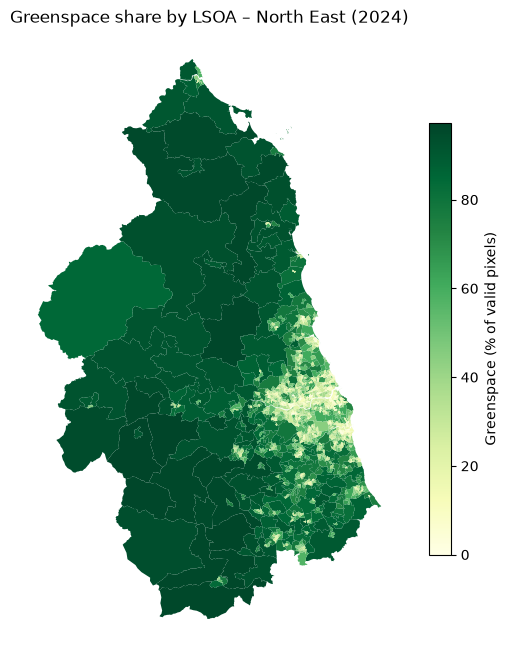

In [8]:
import matplotlib.pyplot as plt

ax = greens.plot(
    column="greenspace_pct",
    legend=True,
    cmap="YlGn",
    figsize=(8, 8),
    linewidth=0,
    legend_kwds={"label": "Greenspace (% of valid pixels)", "shrink": 0.7},
)

ax.set_title("Greenspace share by LSOA – North East (2024)")
ax.set_axis_off()
plt.show()


**Next:** Explore `nodata_ratio`, compare LSOAs, or combine the data with other hackathon datasets. The analysis is up to you.
